1. # Practical 2 report: from relationships to predictive models

**Student:** Yevhenii Zasko  
**Date:** 6.10
**Practical:** 2 - Regression and evaluation


In [101]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import dcor
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml, load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 6102026

In [102]:
diabetes = load_diabetes(as_frame=True)

diabetes_df = diabetes.frame.copy()
diabetes_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. Data-preparation readiness

Complete the checklist before describing modelling results. Tick an item only after checking the data or documenting a justified decision.

### Scientific purpose and provenance

- [x] Is the biological question and prediction task stated clearly?
        **Can baseline physiological measurements predict quantitative diabetes disease progression?**
- [x] Is the unit of observation clear?
    from the table no, some value of sugar in the blood(my guess, but no units of measurements). In the [documentation](https://github.com/scikit-learn/scikit-learn/blob/main/sklearn/datasets/descr/diabetes.rst) there is info for each feature. And target is "Column 11 is a quantitative measure of disease progression one year after baseline", no idea what that means, just some number that represent progression.
- [x] Do I know where the data came from, how they were generated, and under which access conditions they may be used?
- [x] Have I recorded the data version, processing history, and transformations already applied?
    data was scaled "the feature variables are mean centered and scaled by the standard deviation times the square root of n_samples". version "scikit-learn>=1.5", at the moment of development its 1.9.1(stable)

In [103]:
diabetes_df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [104]:
diabetes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


### Table shape and identifiers

- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [x] If needed, have I transposed the original assay into the format expected by the analysis tool?
- [x] Are row names, column names, and identifiers clear, unique, and stable?
    not really, but [here](https://github.com/scikit-learn/scikit-learn/blob/main/sklearn/datasets/descr/diabetes.rst) each data point fairly described
- [x] Can every feature and observation be traced to its source?
    not really, there is no patient id
- [x] Are the feature matrix and metadata aligned by an explicit identifier rather than row order?
    no metadata

### Types, values, and measurement meaning

- [x] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
    not really, all numberical, but sex is categorical(still was scaled, before that it was 0/1 pbbly), age also shouldn't be scaled in my opition. i dont think it will be a problem tho
- [x] Are units, scales, encodings, reference categories, and detection limits understood?
    units of measurement are not provided, but we know they r scaled
- [x] Have impossible values, inconsistent labels, unexpected categories, constant features, and extreme values been checked?
    not really, as they r scaled we dont have the original data, it could've been that the age of the patient is 200 and it was scaled down.
- [x] Are normalization, scaling, log transformation, and batch-correction steps documented?
    yes,  data was scaled "the feature variables are mean centered and scaled by the standard deviation times the square root of n_samples".

### Missing values

- [x] Have missing values been detected using all representations, not only `NaN`?
- [x] Have missing values been measured by row, column, and relevant group?
- [x] Do I know whether missingness is structural, technical, or plausibly related to biology or the target?
- [x] Have retention, removal, or imputation been justified?
- [x] If imputing, will the imputer be fitted on training data only?


everything is present

In [105]:
diabetes_df.isna().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

### Replicates, dependence, and grouping

- [x] Have exact and near-duplicate observations been checked?
- [x] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [x] Is the independent biological unit identified by a grouping variable?
- [x] Will related observations remain in the same train/validation/test split?
- [x] Is the provenance of synthetic or augmented observations recorded?

nothing

Exact duplicate rows 0


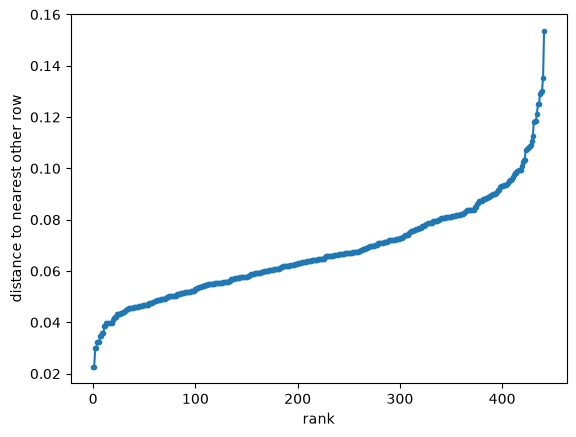

In [106]:
from sklearn.neighbors import NearestNeighbors

print("Exact duplicate rows", int(diabetes_df.duplicated().sum()))

X = diabetes_df.drop(columns="target").to_numpy()
nn = NearestNeighbors(n_neighbors=2).fit(X)
dist, _ = nn.kneighbors(X)
nearest_other = dist[:, 1]          

nearest_other.min(), nearest_other.max()

sorted_d = np.sort(nearest_other)
plt.plot(sorted_d, marker=".")
plt.ylabel("distance to nearest other row")
plt.xlabel("rank")
plt.show()

### Target, leakage, confounding, and reproducibility

- [x] Is the target defined before modelling?
- [x] Have identifiers, post-outcome variables, duplicated target information, and other leakage sources been excluded?
- [x] Have batch, site, subject, treatment, sex, age, time, and other possible confounders been considered?
    age, sex
- [x] Does the planned split represent the biological generalization question?
    default train/test split, sex and age distributed equaly in our case
- [x] Are random seeds, software versions, file names, shapes, and preprocessing decisions recorded?

**Preparation summary:**

- Biological unit: human
- Number of observations and features: features 10, target 1 
- Target and feature definition: target - target, features - age, sex, bmi, bp, s1 tc, s2 ldl, s3 hdl, s4 tch, s5 ltg, s6 glu
- Missing-value decision: no missing value
- Replicate/grouping decision: no replicates found
- Main confounder or leakage source: age, sex
- Train/test split and justification: test/train split 20/80, no need for stratification as the distribution is relativelly balanced 
- Remaining concerns: why did they scale age

In [107]:
diabetes_df["sex"].value_counts()

sex
-0.044642    235
 0.050680    207
Name: count, dtype: int64

In [108]:
diabetes_df["age"].value_counts()

age
 0.016281    19
 0.041708    17
 0.009016    16
-0.027310    15
-0.001882    14
 0.045341    14
-0.052738    14
 0.012648    14
 0.005383    13
 0.067136    13
-0.005515    12
 0.030811    12
 0.001751    12
 0.023546    12
 0.048974    11
-0.009147    11
 0.019913    11
-0.041840    11
 0.038076    10
-0.023677    10
-0.045472     9
 0.027178     9
 0.034443     9
-0.074533     8
 0.070769     7
-0.049105     7
-0.060003     7
 0.059871     7
-0.016412     7
-0.020045     7
 0.063504     6
-0.070900     6
-0.038207     6
-0.056370     6
-0.034575     6
 0.074401     6
-0.085430     5
-0.030942     5
 0.056239     5
 0.081666     5
-0.092695     4
-0.096328     4
-0.063635     4
 0.052606     4
-0.078165     4
-0.012780     4
-0.089063     3
-0.067268     3
-0.107226     3
-0.103593     3
-0.099961     2
-0.081798     2
 0.110727     2
 0.096197     2
 0.085299     1
 0.092564     1
 0.078034     1
 0.088931     1
Name: count, dtype: int64

## 3 Your  task: Diabetes regression

### 3.1 Data presentation

Identify:

- one observation - one patiend;
- the target variable - target column, diseaase progression in one year;
- predictor variables - age, sex, bmi, bp, s1–s6;
- dimensionality of the dataset - (442, 11);
- whether the predictors and target have physical units or transformed scales - features scaled, mean around 0, std around 0.05. target is not scaled 

In [109]:
print(diabetes_df.shape)
diabetes_df.drop(columns="target").describe()


(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


### 3.2 Descriptive analysis

- Summarize the target - disease progression in a year, just some continuous number.
- Visualize its distribution.
- Visualize at least three predictor-target relationships.
- State the biological or predictive question addressed by each plot.

In [110]:
target = diabetes_df["target"]

target.describe()


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

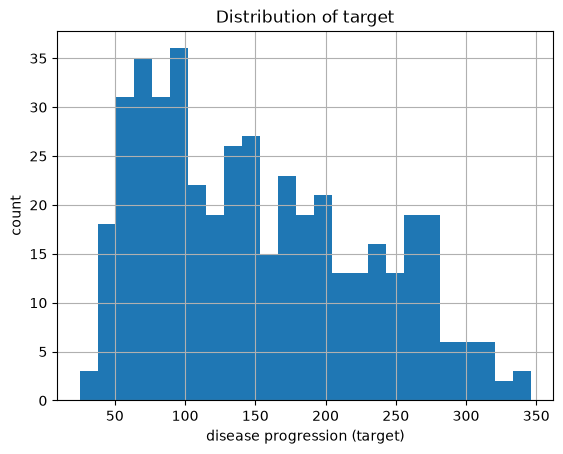

In [111]:

target.hist(bins=25)
plt.xlabel("disease progression (target)")
plt.ylabel("count")
plt.title("Distribution of target")
plt.show()

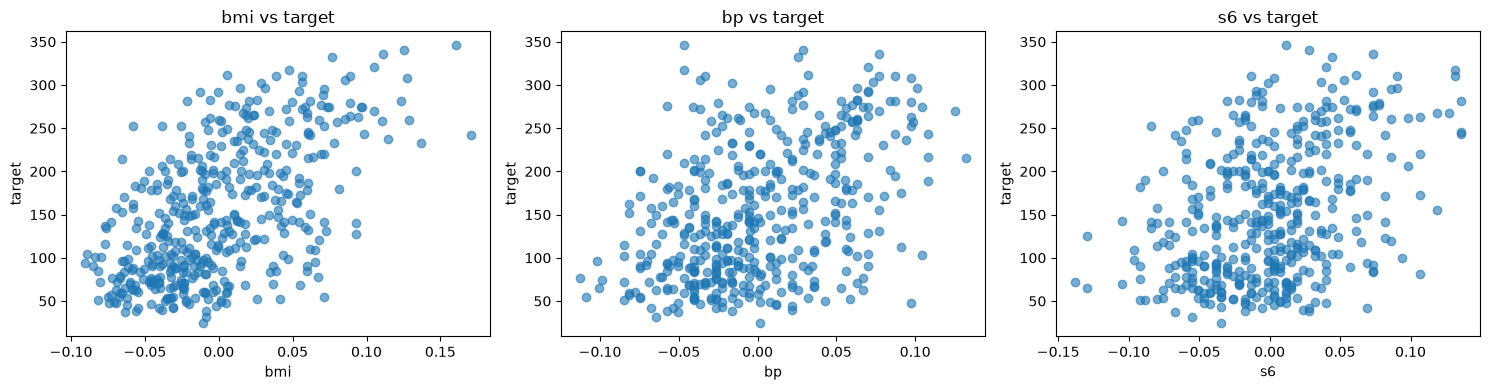

In [112]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["bmi", "bp", "s6"]):
    ax.scatter(diabetes_df[col], target, alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("target")
    ax.set_title(f"{col} vs target")

plt.tight_layout()
plt.show()

1. do patients with higher bmi has faster disease progression, looks linear
2. do patients with higher blood pressure has fater disease progression, looks kinda linear
3. do patients with higher with higher blood sugar level has faster disease progression, it has some linearity signs, but not as visible(which is strange for diabetes, but it might be that in people already with diabetes it doesnt matter as much)

### 3.3 Correlation

- Calculate correlation using ar least 2 different methods.
- Identify the predictor most strongly correlated with the target.
- Compare results.
- Explain why correlation is not sufficient for feature selection or causal interpretation.

In [113]:
diabetes_df.corr(method="pearson")["target"].drop("target").sort_values(ascending=False)

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64

In [114]:
diabetes_df.corr(method="spearman")["target"].drop("target").sort_values(ascending=False)

s5     0.589416
bmi    0.561382
s4     0.448931
bp     0.416241
s6     0.350792
s1     0.232429
age    0.197822
s2     0.195834
sex    0.037401
s3    -0.410022
Name: target, dtype: float64

In [115]:
diabetes_df.corr(method="pearson").style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


in this matrix we see that some features are correlated(s1 and s2 pos corr)(s3 and s4 neg corr)

## Results

most correlated are bmi and s5(first place is based on the correlation approahc)   
the result is pretty similar both in order and in values, some minor exchanges between s5<->bmi, s4<->bp, but values are pretty similar. the correlation between values are pretty linear

correlation is not causation(for interpretation). correlation compares two variables, while it can be/have a confounder and it will be misleading(might add information, but look weak/the other way around)

### 4.4 Simple regression

Choose one predictor and fit a simple linear regression. Report and interpret:

- intercept;
- slope;
- the scale of the predictor;
- whether the slope is a causal effect.

In [116]:
simple_df = diabetes_df[["s5", "target"]]

X_simple = simple_df[["s5"]]
y_simple = simple_df["target"]

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)

print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])

Intercept: 152.13348416289585
Slope: 916.1373745509142


- intercept - 152.13348416289585, target with s5 at 0
- slope - 916.1373745509142, change in target with +1 in s5
- the scale of the predictor - as dataset is normalized we dont have a physical representation of +1 in change of s5, but to answer the question - a change in s5 in 1 relative point will give us increase in 916 points to target(also some relative points for the target). its not a possible case tho as std is aroudn 0.05
- whether the slope is a causal effect - no, its just a relation, both s5 and target might be affected by some other variable and not directly linked between one another



### 4.5 Residual diagnostics

Produce:

- observed versus predicted plot;
- residuals versus fitted plot;
- residual histogram;
- Q-Q plot.

Discuss linearity, homoscedasticity, residual normality, unusual observations, and any limitations of the diagnostics.

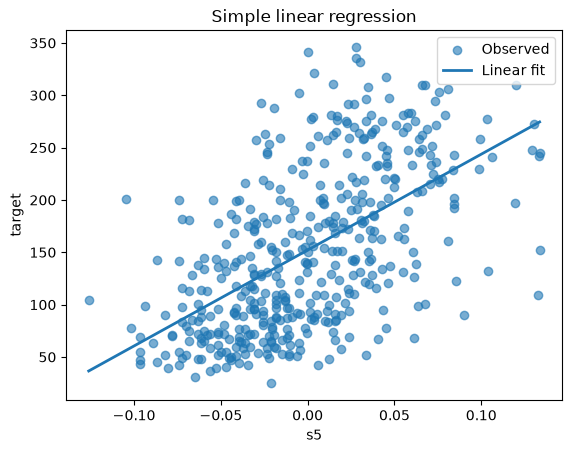

In [117]:
y_hat_simple = simple_model.predict(X_simple)

order = np.argsort(X_simple["s5"].to_numpy())

plt.scatter(X_simple["s5"], y_simple, alpha=0.6, label="Observed")

plt.plot(X_simple["s5"].to_numpy()[order], y_hat_simple[order], linewidth=2, label="Linear fit")

plt.xlabel("s5")
plt.ylabel("target")
plt.title("Simple linear regression")
plt.legend()
plt.show()

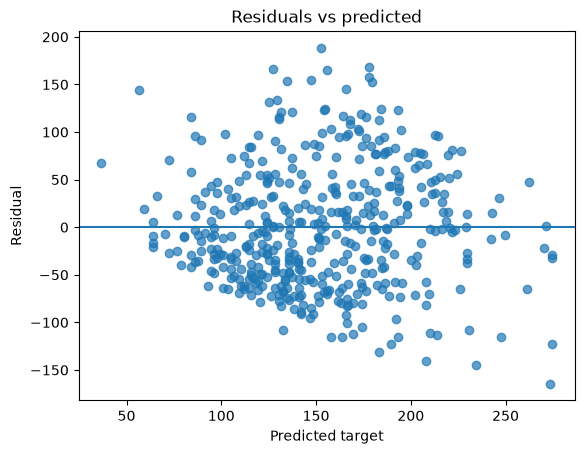

In [118]:
residuals = y_simple.to_numpy() - y_hat_simple

residual_df = pd.DataFrame({
    "observed": y_simple.to_numpy(),
    "predicted": y_hat_simple,
    "residual": residuals})


plt.scatter(
    residual_df["predicted"],
    residual_df["residual"],
    alpha=0.7)

plt.axhline(0)
plt.xlabel("Predicted target")
plt.ylabel("Residual")
plt.title("Residuals vs predicted")
plt.show()

looks a lot like a cone shape to me with residual increase torward the increased predicted target. this is an indication of heteroscedasticity, increase in predicted target results goes together with increased variance. model is less reliable for more severe progression cases

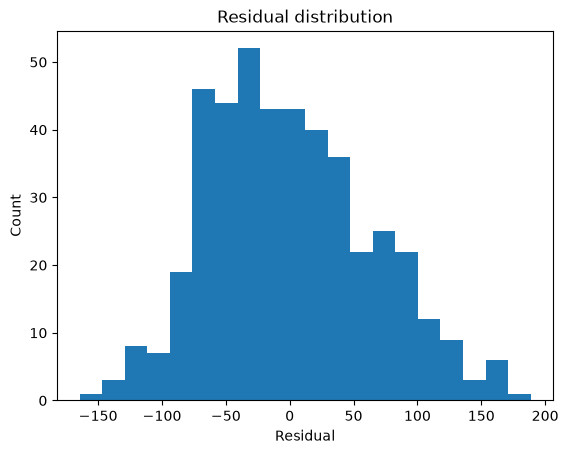

In [119]:
plt.hist(residuals, bins=20)
plt.xlabel("Residual")
plt.ylabel("Count")
plt.title("Residual distribution")
plt.show()

looks like a bell shape with right skew, center arount -30, and has a tail torwards the right
for majority it predict a little bit higher, but for some subset of patients model tend to underpredict a lot

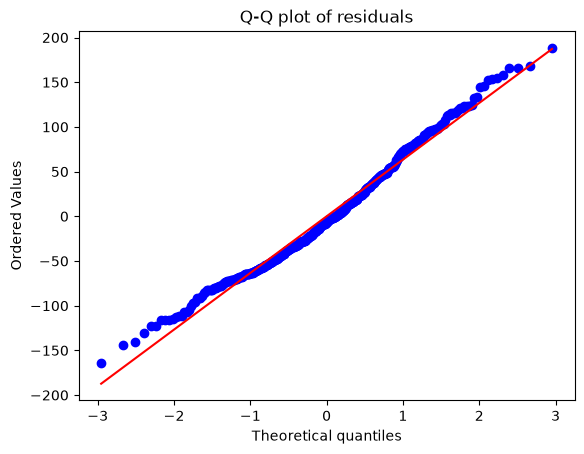

In [120]:
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q plot of residuals")
plt.show()

confirms the previous findings, with deviation on the taills
left side are is negative and right side is more positive than the normal line expects

### 4.6 Multiple regression and multicollinearity

Fit a model using all available predictors. Inspect:

- coefficients;
- predictor correlations;
- possible multicollinearity;
- whether standardized predictors change coefficient interpretation.

In [121]:
X_multi = diabetes_df.drop(columns=["target"])
y = diabetes_df["target"]

multi_model = LinearRegression()
multi_model.fit(X_multi, y)

pd.DataFrame({"feature": X_multi.columns, "coefficient": multi_model.coef_})

,feature,coefficient
0,age,-10.009866
1,sex,-239.815644
2,bmi,519.845920
3,bp,324.384646
4,s1,-792.175639
5,s2,476.739021
6,s3,101.043268
7,s4,177.063238
8,s5,751.273700
9,s6,67.626692


In [122]:
print("Intercept:", multi_model.intercept_)

Intercept: 152.13348416289597


In [123]:
X_multi.corr(method="pearson").style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000


intercept from stayed the same
s5 coef decreased, some values took some of the variation "explanation" from it, still slope is pretty high for it

one problem with multilinear model is that if two coefs are correlated they both might have high slopes but cancel each other out, thats the probable case for s1/s2(multicolinearity)

regarding the coeff interpretation - yes, as they are all normalized we can compare relative strength of each feature on the result, even tho we cannot draw the physical interpretation

In [124]:
numeric_features = ["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
categorical_features = ["sex"]

preprocessor = ColumnTransformer(transformers=[
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

cat_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LinearRegression()),
])
cat_model.fit(X_multi, y)

feature_names = cat_model.named_steps["preprocess"].get_feature_names_out()
coefs = cat_model.named_steps["model"].coef_
pd.DataFrame({"feature": feature_names, "coefficient": coefs})

,feature,coefficient
0,num__age,-10.009866
1,num__bmi,519.845920
2,num__bp,324.384646
3,num__s1,-792.175639
4,num__s2,476.739021
5,num__s3,101.043268
6,num__s4,177.063238
7,num__s5,751.273700
8,num__s6,67.626692
9,cat__sex_0.05068011873981862,-22.859648


at first i run the sex as numbered param and its slope was around 200, but it was misleading, we cannot interpret change in +1 for categorical values even if they are represented as numbers, this value of -22 is the difference between groups influence on target(im not sure what number is male and what is female, but the group(pbbly females) with higher number has on average -22 to the target than the other group)

### 4.7 Train/test evaluation

Create a justified train/test split and report MAE, MSE, RMSE, and $R^2$. Compare simple and multiple regression on test data.

Explain whether the split answers the intended biological or clinical generalization question.

In [127]:
X_train, X_test, y_train, y_test = train_test_split(
    X_multi, y, test_size=0.2, random_state=RANDOM_STATE
)

In [126]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}

In [128]:
results = []
simple_eval = LinearRegression()
simple_eval.fit(X_train[["s5"]], y_train)

for split_name, X_split, y_split in [("train", X_train, y_train), ("test", X_test, y_test)]:
    pred = simple_eval.predict(X_split[["s5"]])
    results.append({"model": "Simple (s5)", "split": split_name, **regression_metrics(y_split, pred)})

cat_model_eval = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LinearRegression()),
])
cat_model_eval.fit(X_train, y_train)

for split_name, X_split, y_split in [("train", X_train, y_train), ("test", X_test, y_test)]:
    pred = cat_model_eval.predict(X_split)
    results.append({"model": "Multiple (all predictors)", "split": split_name, **regression_metrics(y_split, pred)})

pd.DataFrame(results)

,model,split,MAE,MSE,RMSE,R2
0,Simple (s5),train,51.610155,4092.347607,63.971459,0.306584
1,Simple (s5),test,50.997606,3790.826780,61.569690,0.370128
2,Multiple (all predictors),train,42.878038,2825.460696,53.155063,0.521248
3,Multiple (all predictors),test,46.325865,3096.291767,55.644333,0.485529


split is ok in this case, each entry is different patient(no grouping needed to prevent leakage), distributino of age(as shown before) is equal, no stratification needed

### 4.8 Independent-task conclusion

Answer:

1. Which model generalized better? - multilinear regression
2. Did adding more variables help? - yes, test R^2 went from 0.370 to 0.486, and errors decreased(table above)
3. Are any regression assumptions questionable? - yes, regarding the influence of each feature on the result as some of them are correlated
4. Are coefficient interpretations straightforward? - no, at least physical interpretation cannot be done as the dataset is normalized, but we can compare influence of each feature on the result
5. What is one important limitation of the dataset or model? - heteroscedasticity of the predicted targets

Remember that the predictors from `load_diabetes()` are already standardized.